In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import os

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D 
from matplotlib import gridspec
import seaborn as sns

import scanpy as sc
import scvi


/home/syyang/python_virtuenv/mrvi_3.11/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/syyang/python_virtuenv/mrvi_3.11/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/syyang/python_virtuenv/mrvi_3.11/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/syyang/python_virtuenv/mrvi_3.11/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing CSCDataset from `anndata.experimental` is deprecated. Import anndata.abc.CSCDataset instead.
  warnings.warn(msg, FutureWarning)
/home/syyang/python_virtuenv/mrvi_3.11/lib/python3.11/site-packages/anndat

# Load Data

## Load entropy results

In [2]:
entropy_dir = '/mnt/hdd_bob/syy/adipose/atac/res/VIB_10xmultiome_2_WS3000F'

Union_cell_subdir = os.path.join(entropy_dir, '_cell_calling_comparison')
Union_cell_all_info_file = os.path.join(Union_cell_subdir, 'Union_cell_3set_w_RNAQC.tsv')
Union_cell_all_info = pd.read_csv(Union_cell_all_info_file, sep='\t', index_col=0)
union_cell_info = Union_cell_all_info[Union_cell_all_info['_3set_identified_by_atac'] != 'none']
union_cell_info.head(2)


,total_fragments,atac_pass_CR,atac_pass_entropy,atac_pass_archr_TSS,_2set_identified_by_atac_SC,_2set_identified_by_atac_ST,_3set_identified_by_atac,Entropy,DNA_debris,P_closed_state,atac_barcodes.1,rna_bc,rna_pass_CR
atac_barcodes,,,,,,,,,,,,,
AAACAAGCAAGTTAGT-1,2412,True,True,True,both,both,common,0.218328,NO,0.965116,AAACAAGCAAGTTAGT,GGCTAGTGTGTTAGCA,True
AAACAAGCATTTCTTC-1,9030,True,True,True,both,both,common,0.074451,NO,0.990949,AAACAAGCATTTCTTC,GGCTAGTGTACGTTTC,True


# RNA clustering

In [3]:
h5_rna_union_file = os.path.join(Union_cell_subdir, 'Union_3set_rna.h5ad')

h5_rna_union = sc.read_h5ad(h5_rna_union_file)

/home/syyang/python_virtuenv/mrvi_3.11/lib/python3.11/site-packages/anndata/_core/anndata.py:1760: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [4]:
h5_rna_union, h5_rna_union.shape 

(AnnData object with n_obs × n_vars = 2381 × 36601
     obs: 'rna_barcodes', 'atac_barcodes', 'total_RNA_UMI', 'total_RNA_UMI_log', 'n_genes_by_RNA_counts', 'N_MT_counts', 'MT%'
     var: 'gene_ids', 'feature_types', 'genome',
 (2381, 36601))

In [5]:
sc.pp.filter_genes(h5_rna_union, min_counts=3)
h5_rna_union.raw = h5_rna_union # keep full dimension safe
h5_rna_union.layers['counts'] = h5_rna_union.X
sc.pp.highly_variable_genes(
h5_rna_union    ,
flavor="seurat_v3",
n_top_genes=4000,
layer="counts",
subset=False)


# Normalization for visualization
h5_rna_union.layers['log1p_counts'] = np.log1p(h5_rna_union.X)
h5_rna_union.layers['cpm'] = sc.pp.normalize_total(h5_rna_union, target_sum=1e4, inplace=False)['X']
h5_rna_union.layers['log1p_cpm'] = np.log1p(h5_rna_union.layers['cpm'])

/home/syyang/python_virtuenv/mrvi_3.11/lib/python3.11/site-packages/anndata/_core/anndata.py:1760: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/syyang/python_virtuenv/mrvi_3.11/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


In [6]:
SCVI_LATENT_KEY = "RNA_scVI"
SCVI_CLUSTERS_KEY = "leiden_RNA_scVI"


vae_model_folder=os.path.join(entropy_dir, "_unioncells_RNA_scvi_model")
vae =scvi.model.SCVI.load(vae_model_folder, adata=h5_rna_union)
h5_rna_union.obsm[SCVI_LATENT_KEY] = vae.get_latent_representation()


# clustering using scVI latent representation via Leiden
atac_resolution = 0.5
sc.pp.neighbors(h5_rna_union, use_rep=SCVI_LATENT_KEY)
sc.tl.umap(h5_rna_union, min_dist=0.5)
sc.tl.leiden(h5_rna_union, key_added=SCVI_CLUSTERS_KEY, resolution=atac_resolution + 0.1)

INFO     File /mnt/hdd_bob/syy/adipose/atac/res/VIB_10xmultiome_2_WS3000F/_unioncells_RNA_scvi_model/model.pt      
         already downloaded                                                                                        


/home/syyang/python_virtuenv/mrvi_3.11/lib/python3.11/site-packages/scvi/model/base/_save_load.py:76: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model = torch.load(model_

### Vis on RNA spcae

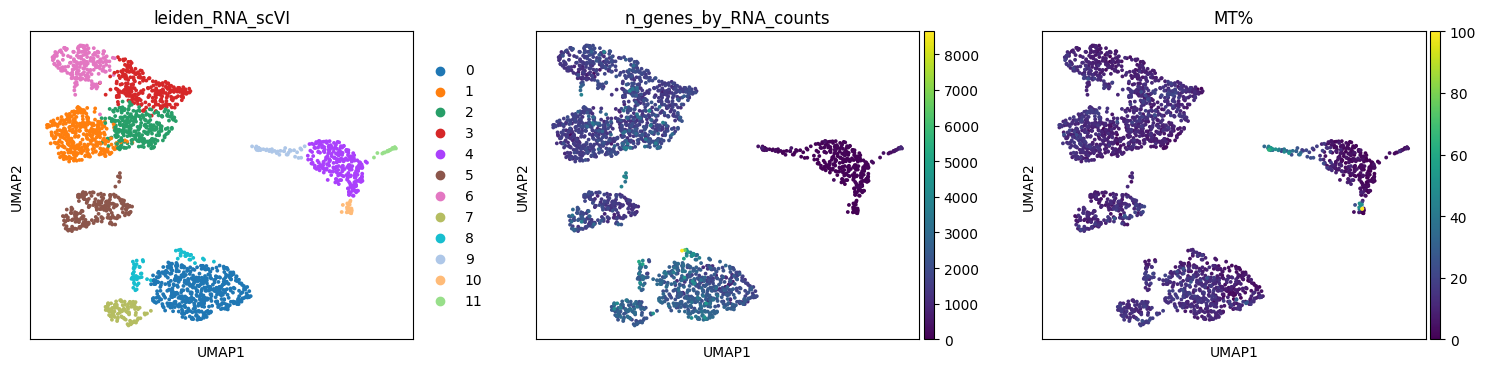

In [8]:
with plt.rc_context({'figure.figsize': (5, 4)}):
    sc.pl.umap(h5_rna_union, color=['leiden_RNA_scVI',  'n_genes_by_RNA_counts', 'MT%'], wspace=0.2, size=30, ncols=3)

In [11]:
h5_rna_union.obs

,rna_barcodes,atac_barcodes,total_RNA_UMI,total_RNA_UMI_log,n_genes_by_RNA_counts,N_MT_counts,MT%,_scvi_batch,_scvi_labels,leiden_RNA_scVI,_2set_identified_by_atac_SC,_2set_identified_by_atac_ST,_3set_identified_by_atac,rna_pass_CR
AAACAGCCAGGCTACT-1,AAACAGCCAGGCTACT,ACAGCGGGTTTGTAGC,3931.0,8.276903,1772,519.0,13.202747,0,0,1,NaN,NaN,NaN,NaN
AAACATGCAAGGATTA-1,AAACATGCAAGGATTA,CATTTAGGTAACAGCA,3566.0,8.179481,1689,401.0,11.245092,0,0,3,NaN,NaN,NaN,NaN
AAACATGCACCTGGTG-1,AAACATGCACCTGGTG,CATTTAGGTTAATCCA,3552.0,8.175548,1640,290.0,8.164414,0,0,5,NaN,NaN,NaN,NaN
AAACATGCAGAACCGA-1,AAACATGCAGAACCGA,CATTTAGGTTAATCGC,2858.0,7.958227,1390,471.0,16.480055,0,0,1,NaN,NaN,NaN,NaN
AAACCAACACATACTG-1,AAACCAACACATACTG,CTTTATCGTCGGTTCA,4002.0,8.294800,1863,295.0,7.371315,0,0,6,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCTAGGCAGGTG-1,TTTGTCTAGGCAGGTG,TGTCAATTCGGGATGC,5775.0,8.661467,2297,255.0,4.415585,0,0,0,NaN,NaN,NaN,NaN
TTTGTGAAGGCATTAC-1,TTTGTGAAGGCATTAC,GTAGGTGTCAAAGGGA,7385.0,8.907342,2631,688.0,9.316181,0,0,0,NaN,NaN,NaN,NaN
TTTGTGGCAATAATCC-1,TTTGTGGCAATAATCC,GTTTGGTGTAGGTTCT,3912.0,8.272059,1828,466.0,11.912066,0,0,2,NaN,NaN,NaN,NaN
TTTGTGGCACCTAAGC-1,TTTGTGGCACCTAAGC,GTTTGGTGTATCGCTG,4232.0,8.350666,1880,404.0,9.546313,0,0,2,NaN,NaN,NaN,NaN


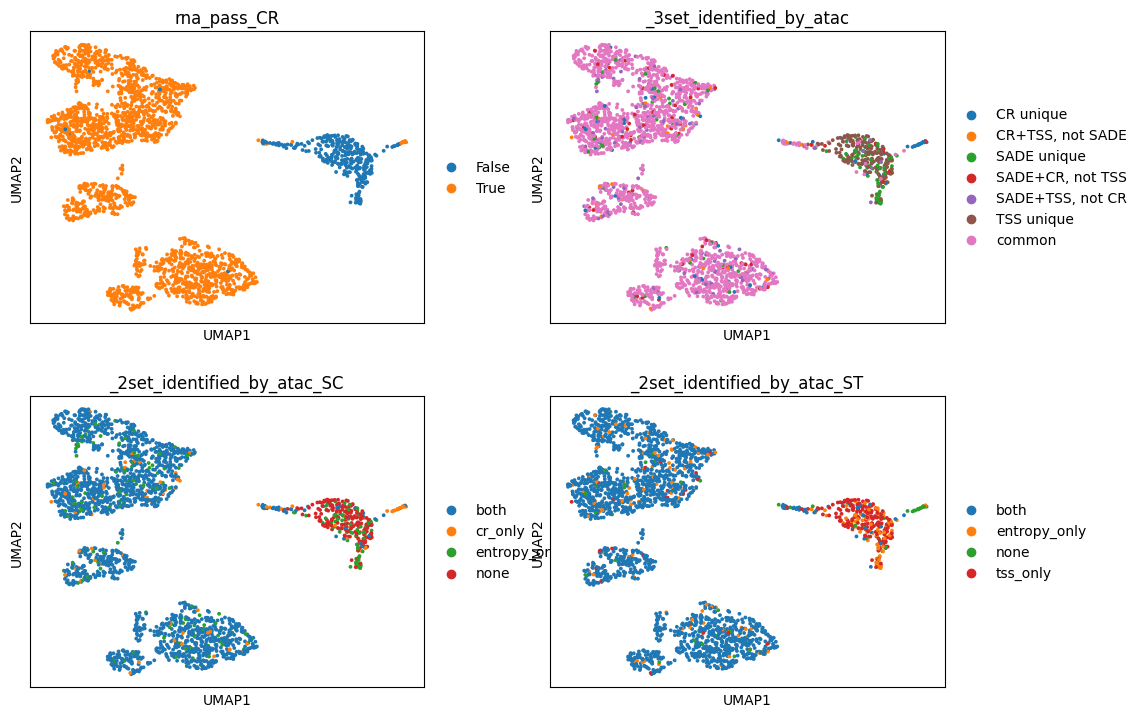

In [12]:
col_list = ['_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 
            'rna_pass_CR']
h5_rna_union.obs['atac_bc'] = h5_rna_union.obs['atac_barcodes'].map(lambda x: x + '-1')
for col in col_list:
    h5_rna_union.obs[col] = h5_rna_union.obs['atac_bc'].map(union_cell_info[col])

with plt.rc_context({'figure.figsize': (5, 4)}):
    sc.pl.umap(h5_rna_union, color=[
                              'rna_pass_CR', '_3set_identified_by_atac',
                              '_2set_identified_by_atac_SC',
                                    '_2set_identified_by_atac_ST',   ] , wspace=0.2, size=30, ncols=2)

In [13]:
Tcells= ['IL7R',] #'CD3G', 'CD3E', 'CD3D',  ] 
B_cell = ['MS4A1', 'CD79A']# , 'CD19', ]
NK = [ 'FCGR3A', 'NCAM1'] # NKG7',FCGR3A', 'NCAM1'
mono = [ 'CD14',   'CD68',   ]# ,  CD14, FCGR1A, CD68
naiveTcells = [ "CCR7",	  ]#  "CCR7",	 'IL7R',
DC=[  'CD1C',    'SERPINF1']
cytotoxic_T = ['CD8A', 'CD8B',]
mono_or_DC = ['HLA-DRA'] # for umap 
naiveThelper = [   'CD4', ] # for umap 

housekeeping_genes = ['GNB1', 'PRPF38B',  'CDC42SE1', 'PPP2R5A',] # 'CMPK1', 'COX7A2L', 'SF3B1', 'CTDSP1']

marker_genes =Tcells  + naiveTcells +  cytotoxic_T+  NK+ mono + DC + B_cell    + mono_or_DC + naiveThelper + housekeeping_genes 

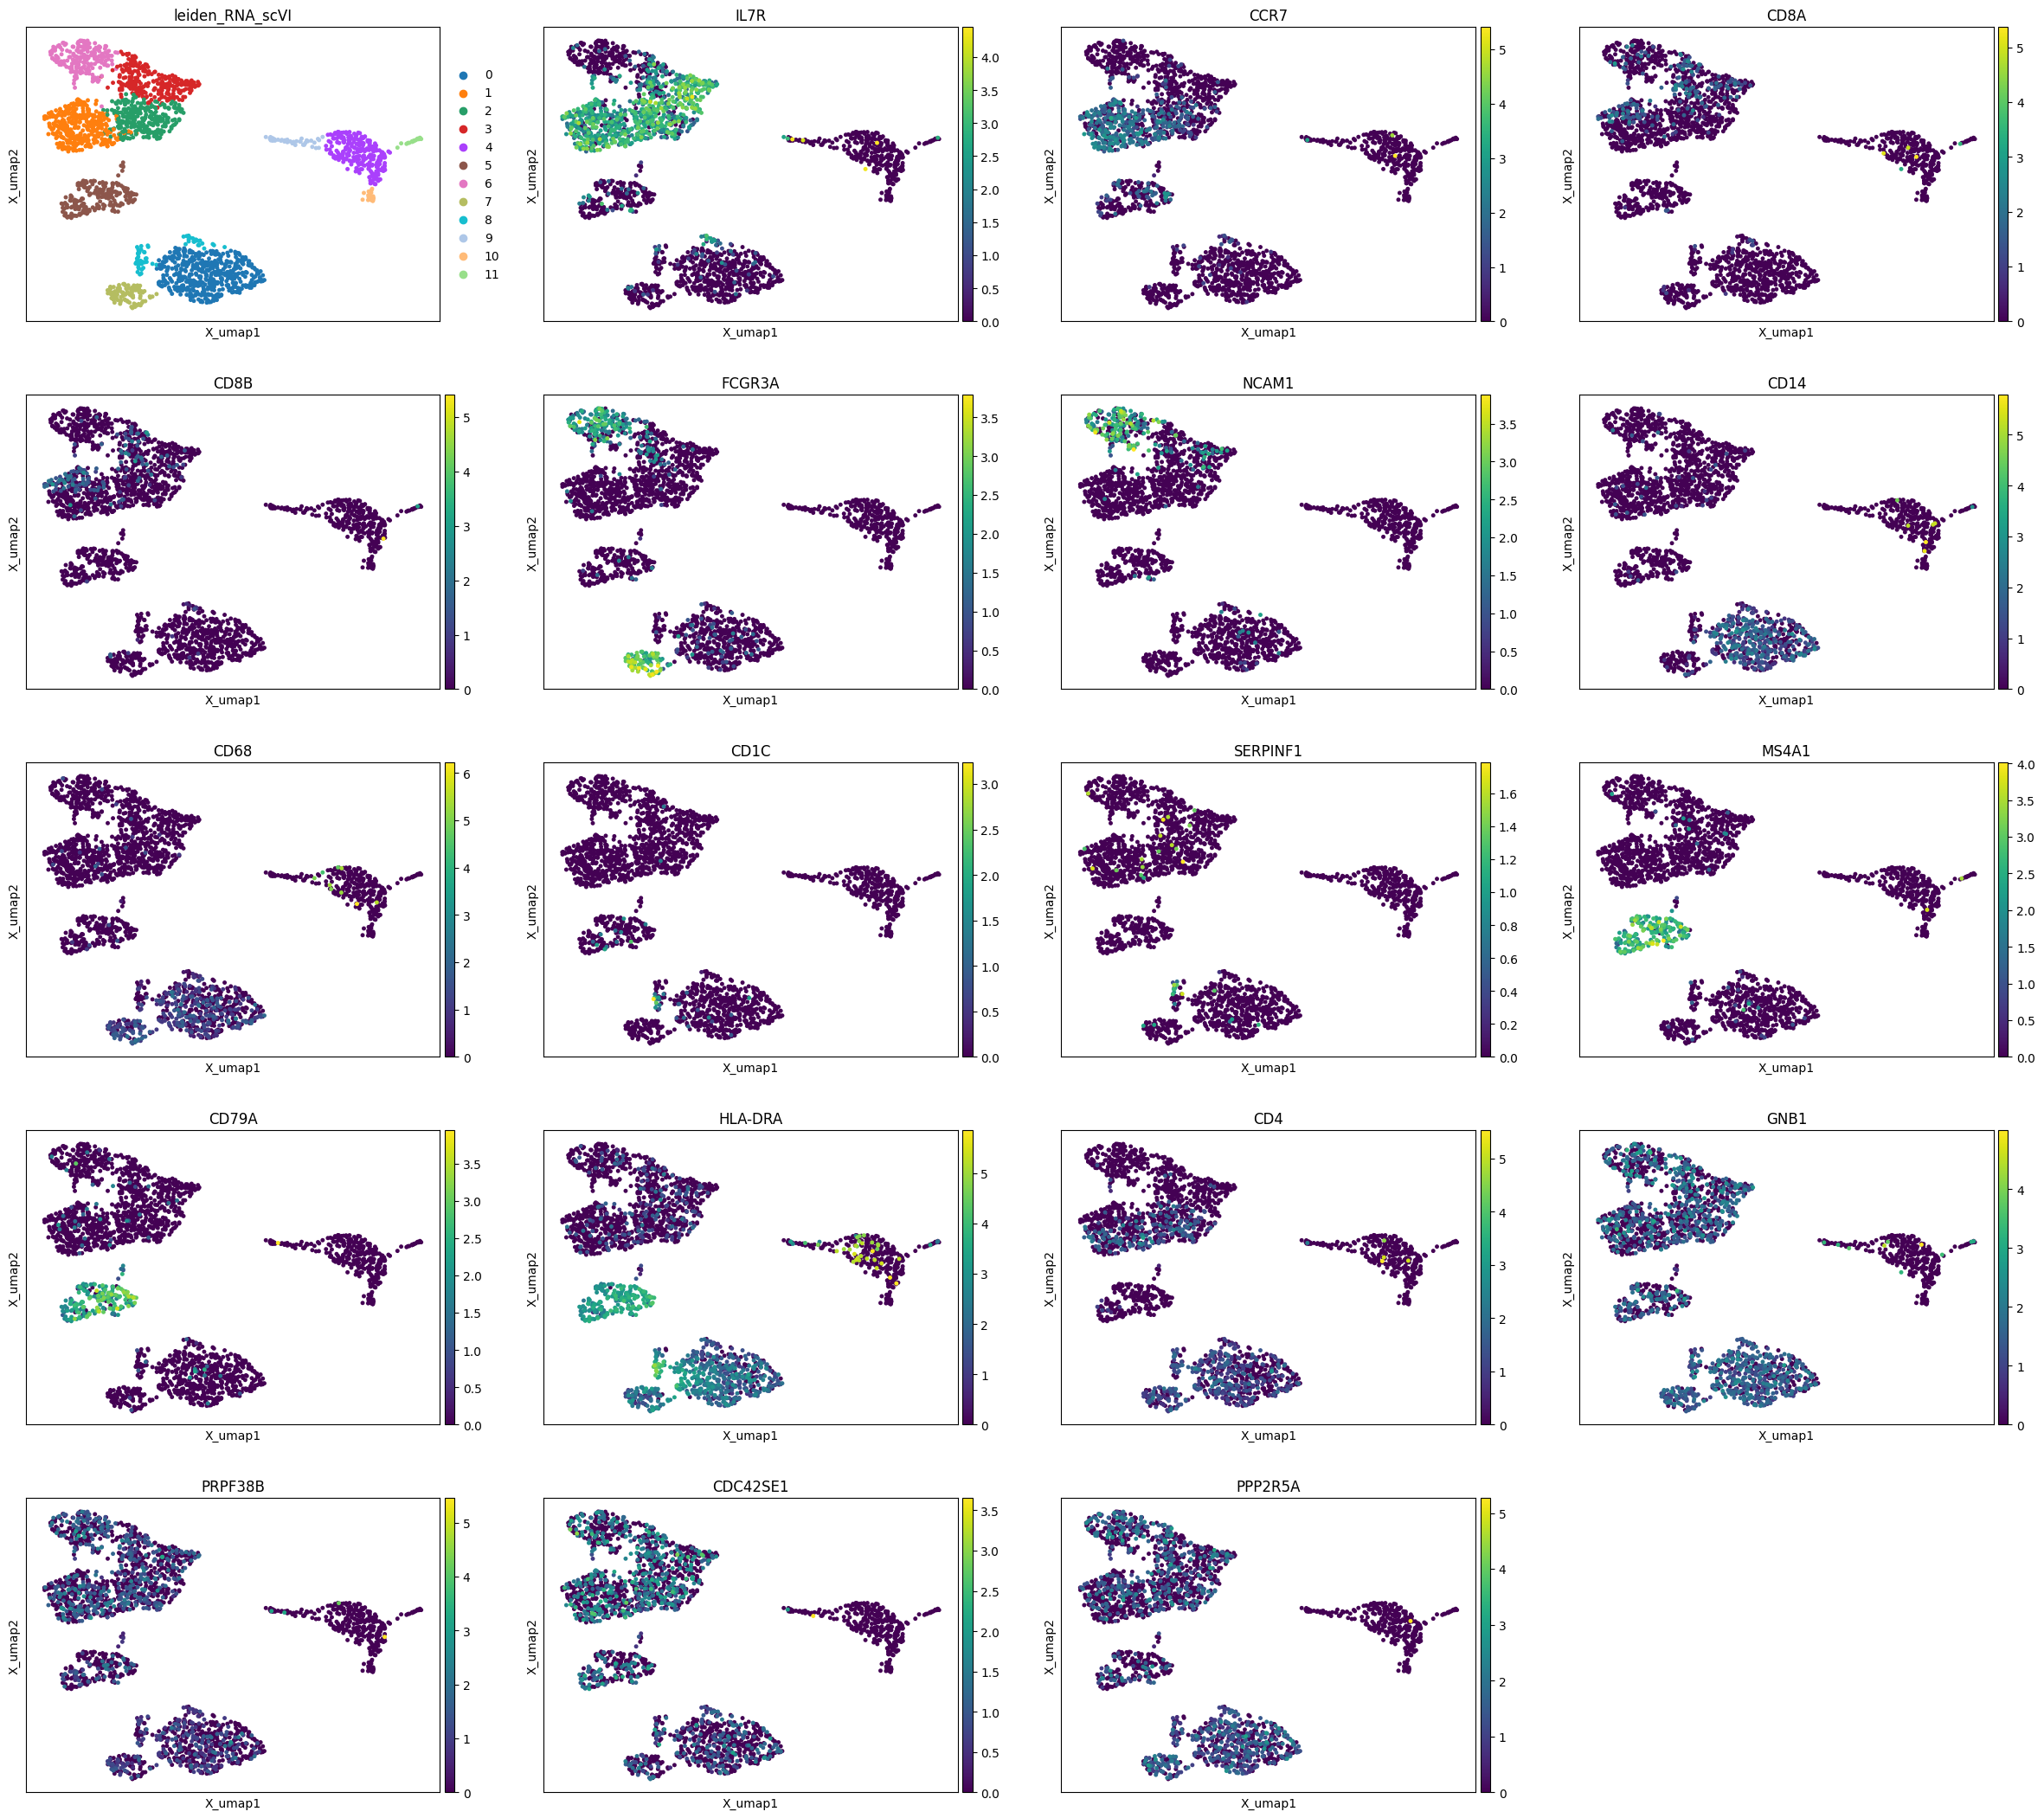

In [14]:

sc.pl.embedding(h5_rna_union, basis="X_umap", layer='log1p_cpm', color=["leiden_RNA_scVI",] + \
     marker_genes)

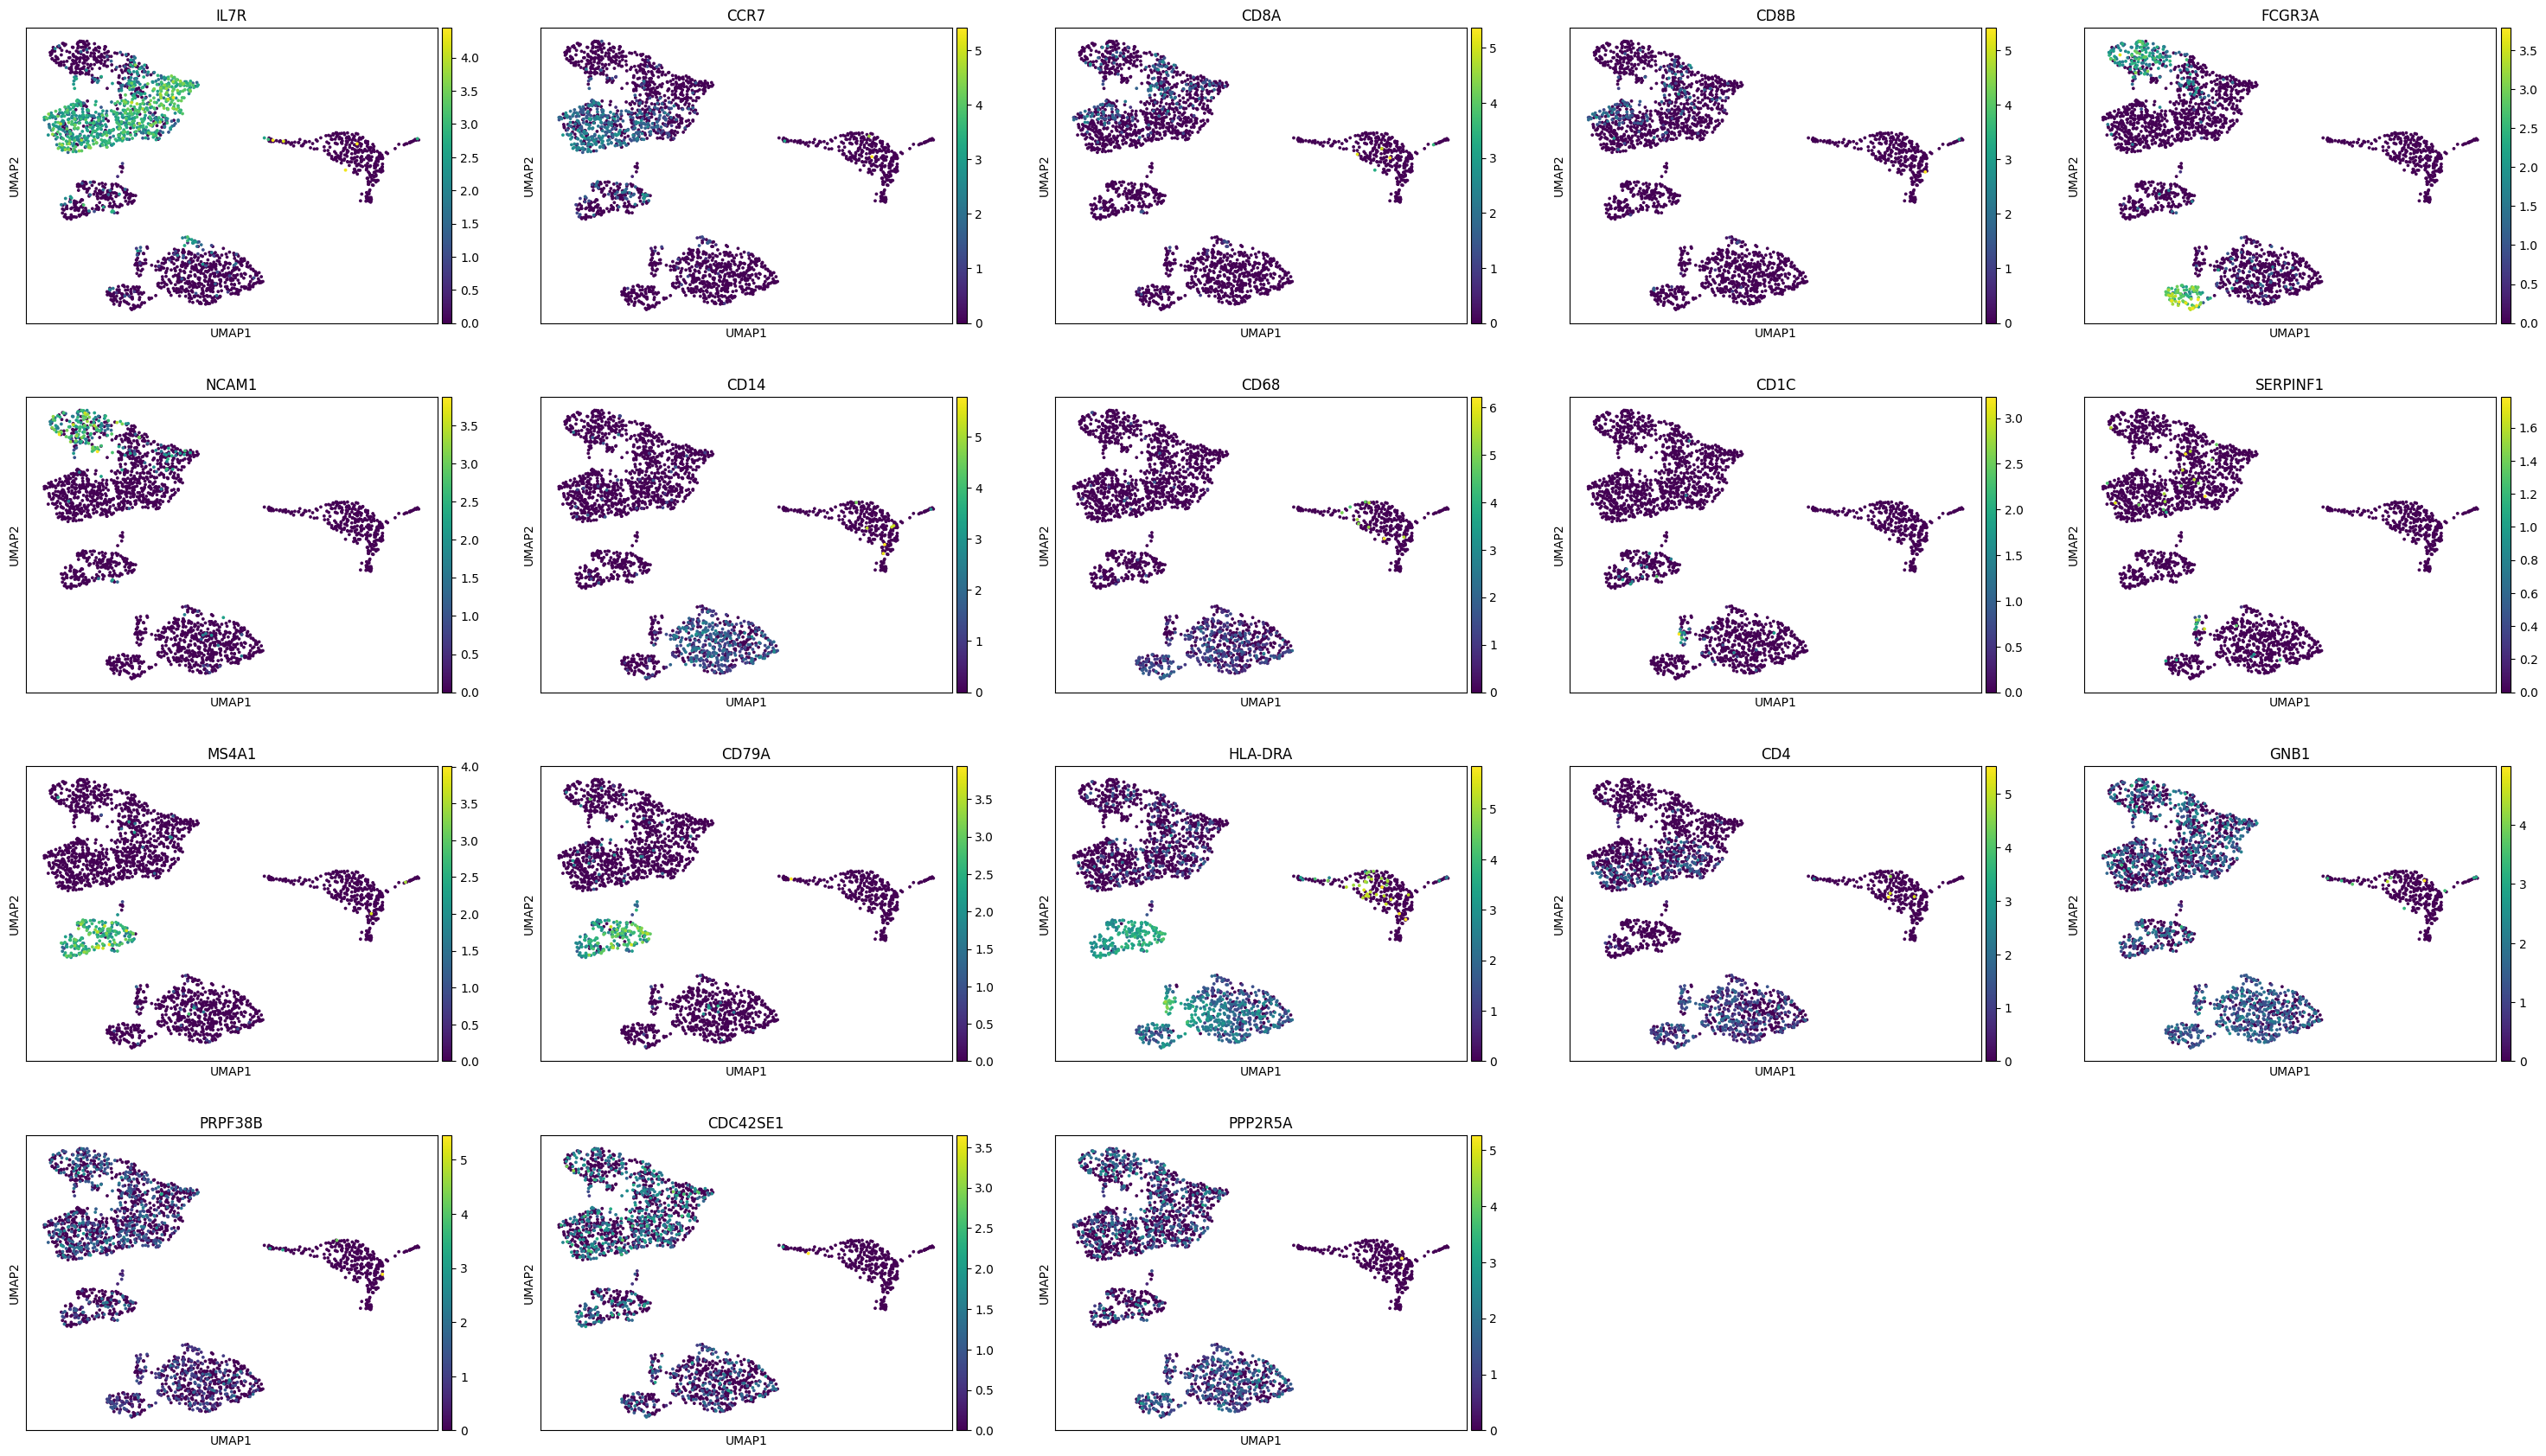

In [15]:
sc.pl.umap(h5_rna_union, color=marker_genes,  layer='log1p_cpm', size=30, ncols=5)

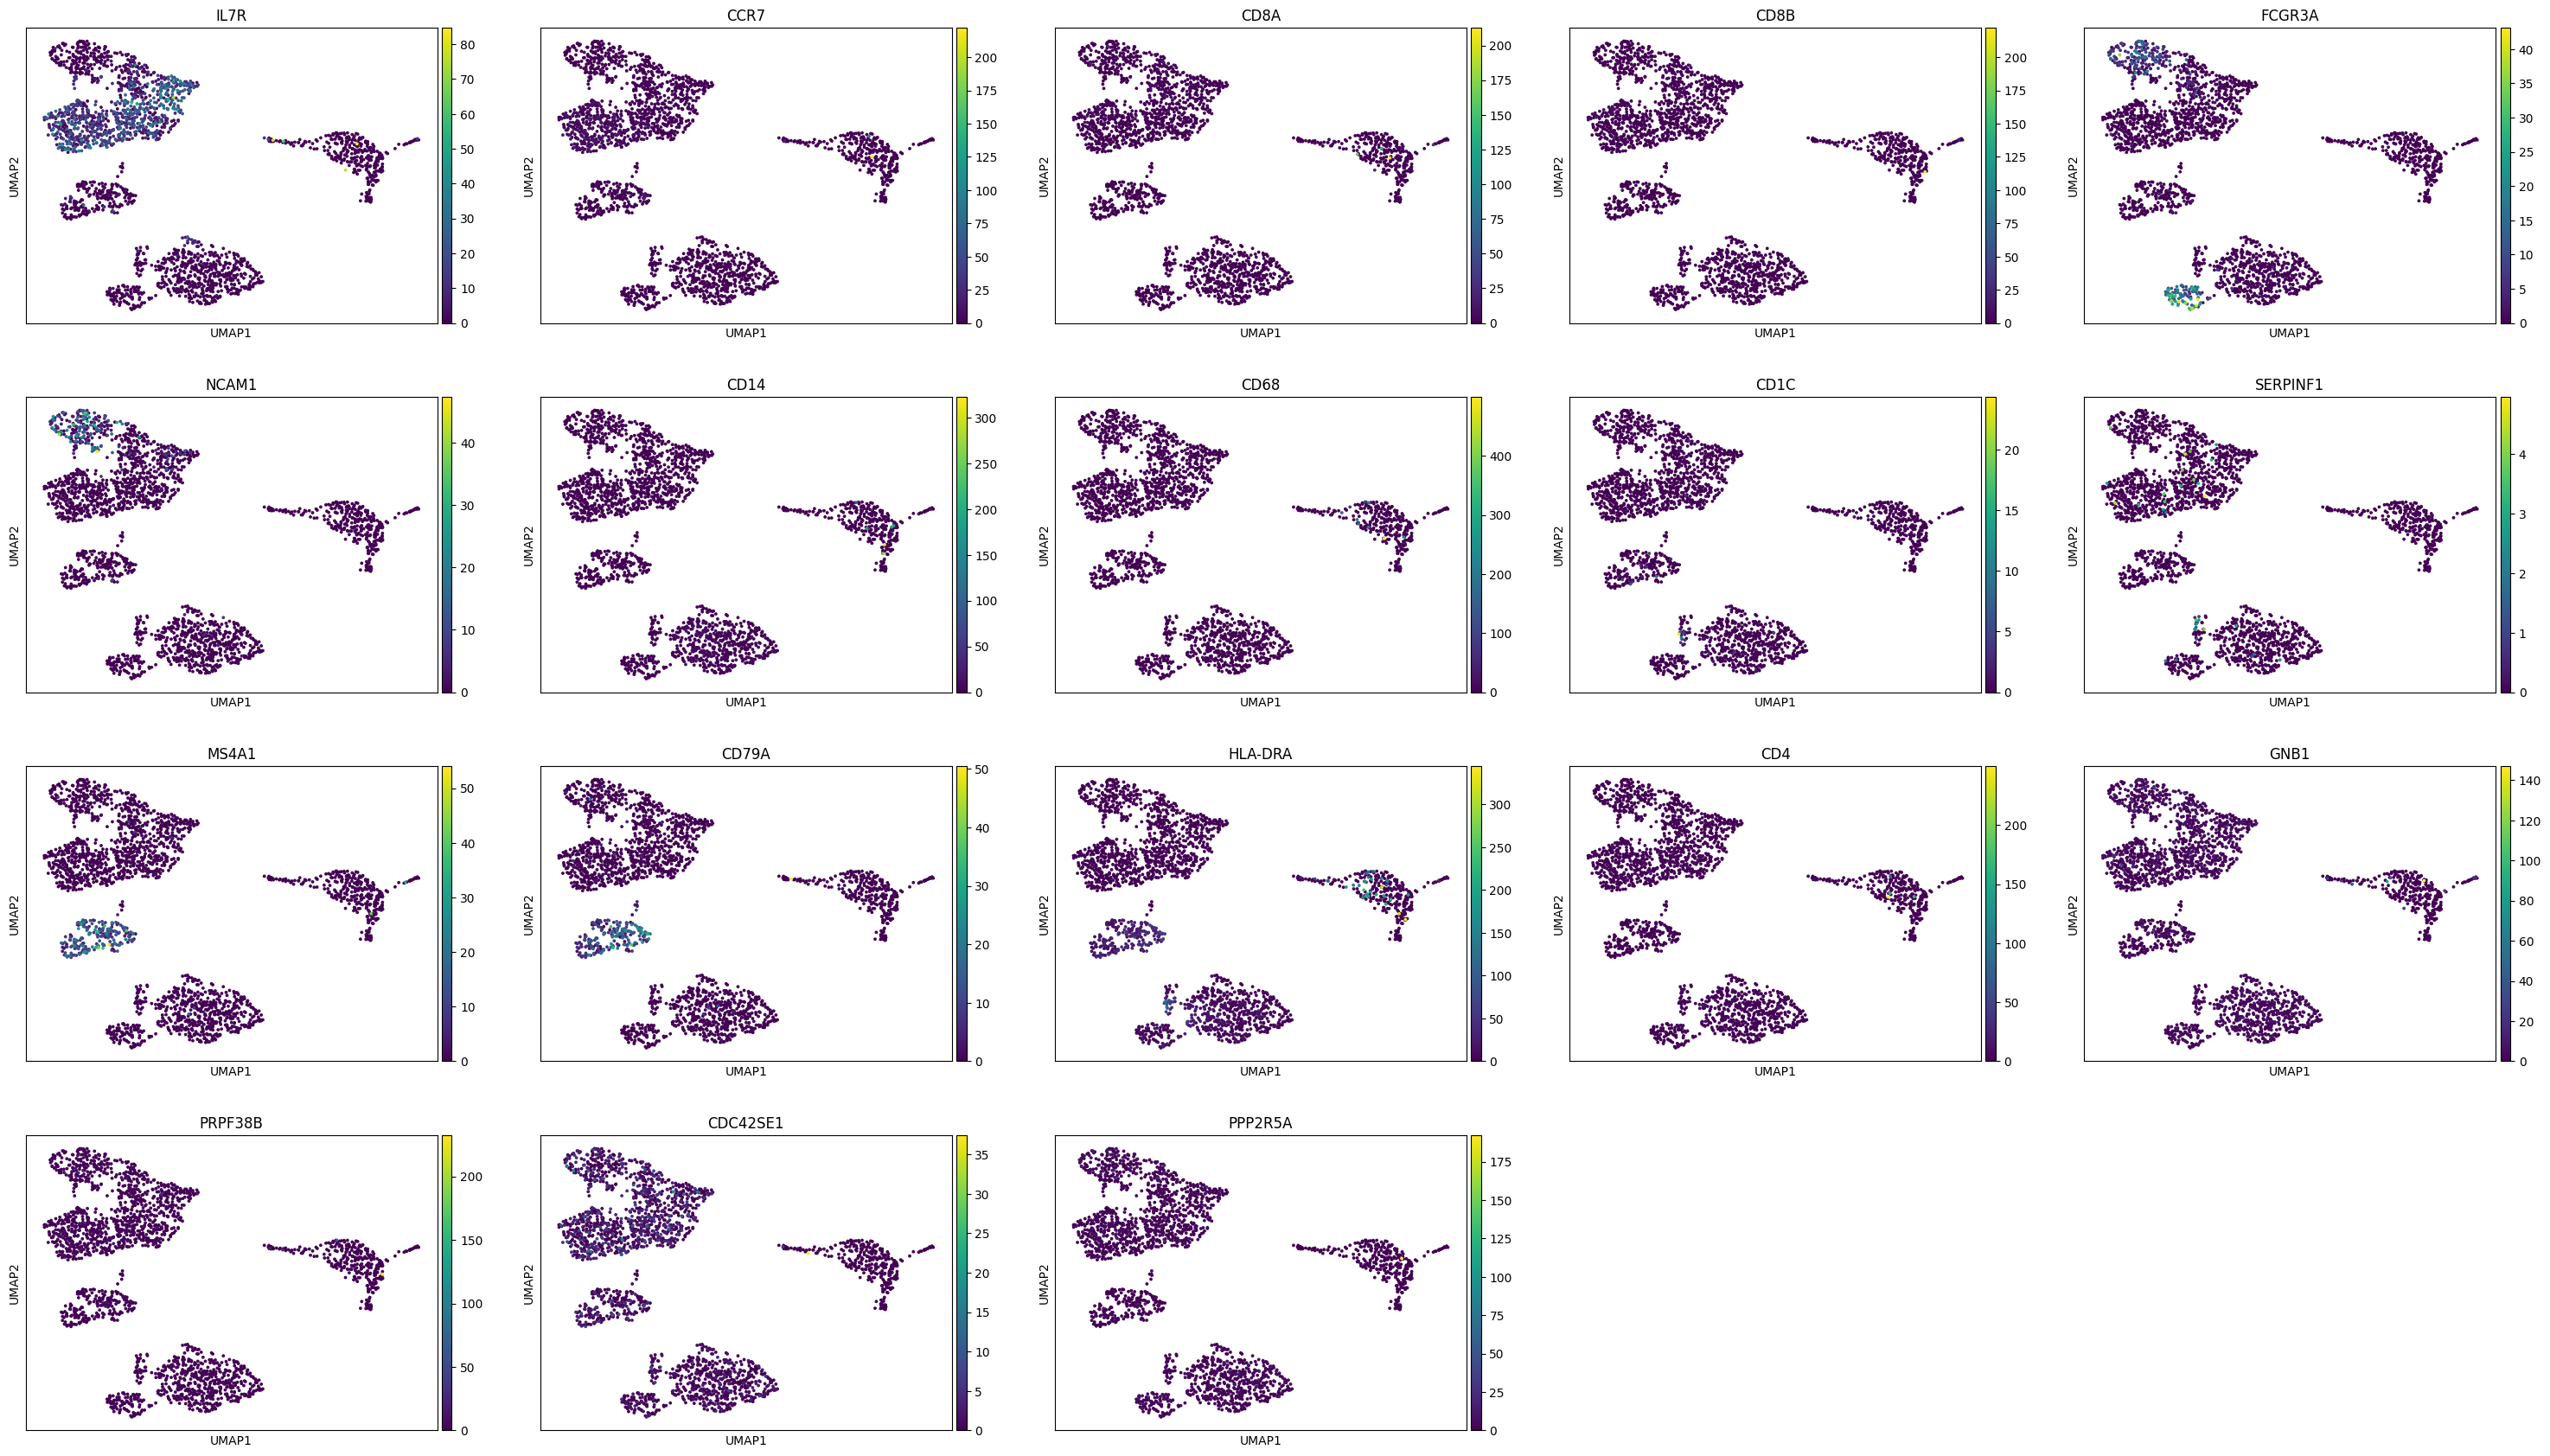

In [16]:

sc.pl.umap(h5_rna_union, color=marker_genes,  layer='cpm', size=30, ncols=5)

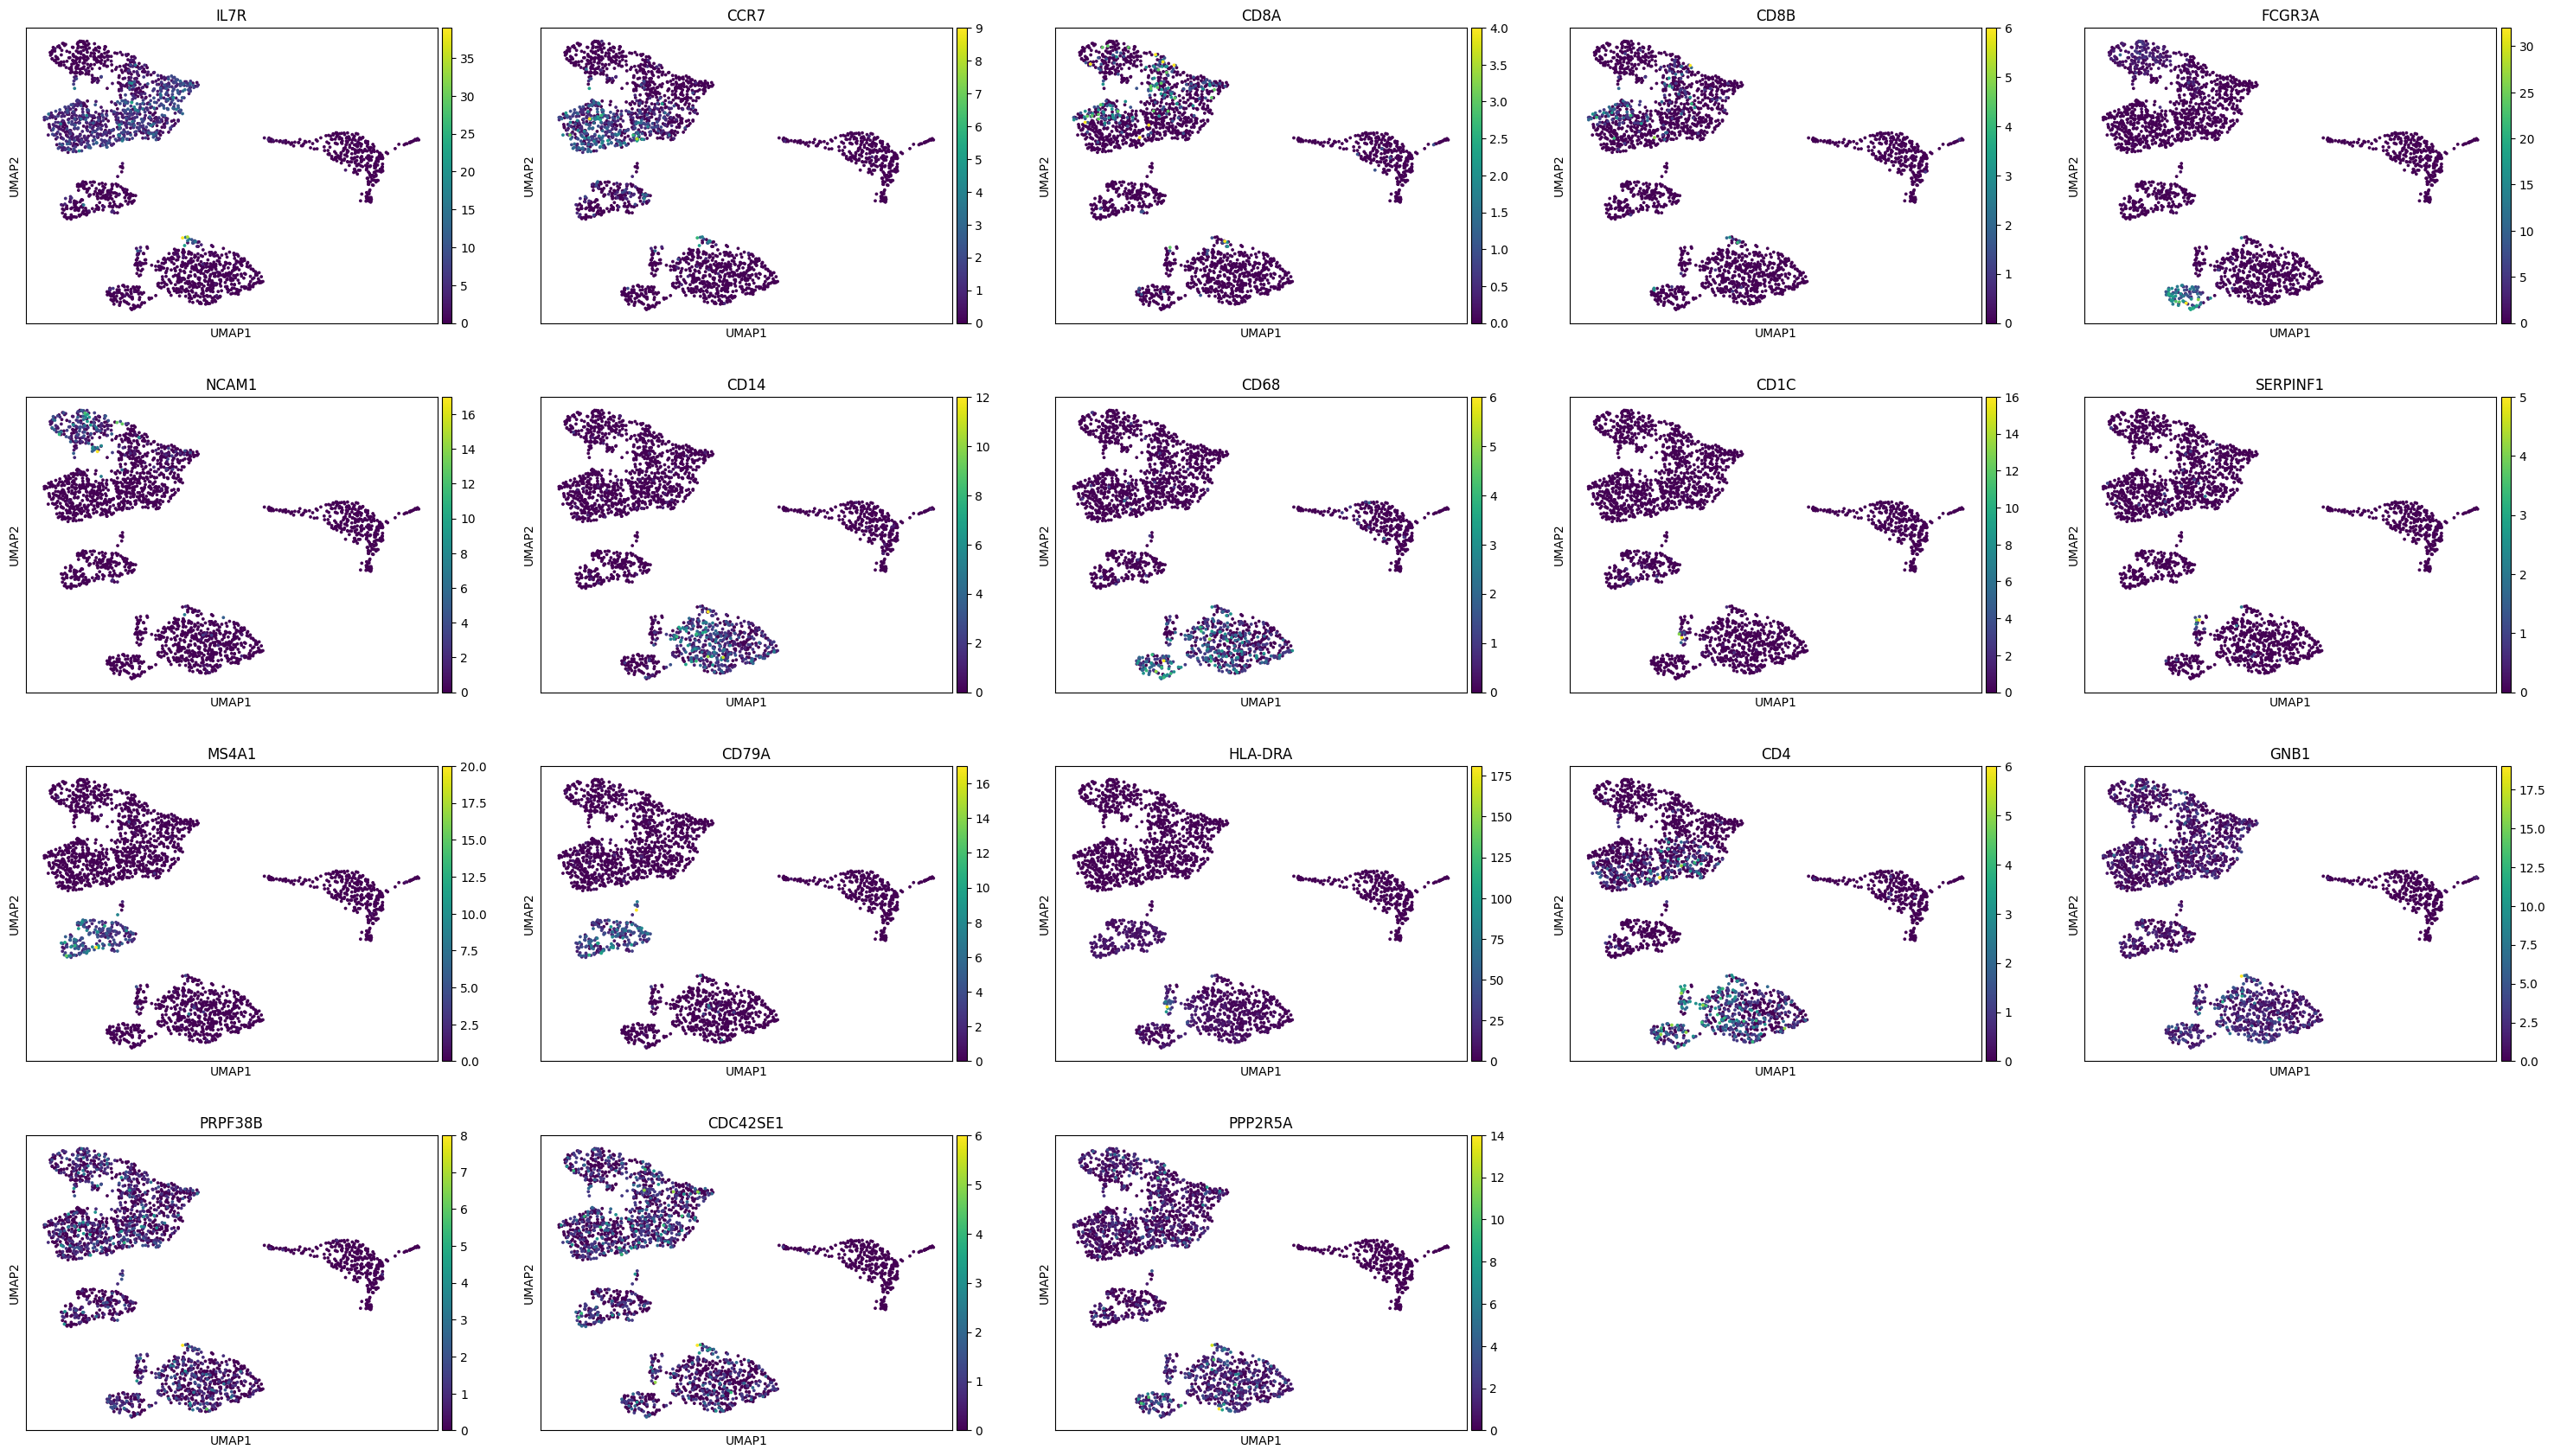

In [17]:
sc.pl.umap(h5_rna_union, color=marker_genes,  size=30, ncols=5)

In [20]:
## Save cluster average gene 
cluster_average_df = pd.DataFrame(index=h5_rna_union.var_names)


for c in h5_rna_union.obs['leiden_RNA_scVI'].unique():
    a = h5_rna_union[h5_rna_union.obs['leiden_RNA_scVI'] == c, :].layers['log1p_cpm'].mean(axis=0)
    cluster_average_df[c] = np.asarray(a).flatten()


gene_activity_file = os.path.join(Union_cell_subdir, '_SCVI_RNAanalysis', 'RNA_cluster_average_gene_expression.csv')
if not os.path.exists(os.path.dirname(gene_activity_file)):
    os.makedirs(os.path.dirname(gene_activity_file))
cluster_average_df.to_csv(gene_activity_file)

cluster_average_df.head()

,1,3,5,6,2,0,8,4,7,10,11,9
AL627309.1,0.006676,0.010664,0.000000,0.000000,0.000000,0.023448,0.028823,0.000000,0.017335,0.0,0.0,0.0
AL627309.5,0.018079,0.000000,0.017699,0.015902,0.005922,0.085301,0.071682,0.016718,0.086362,0.0,0.0,0.0
AL627309.4,0.000000,0.000000,0.000000,0.000000,0.000000,0.023221,0.017299,0.000000,0.030979,0.0,0.0,0.0
AL669831.2,0.009104,0.005188,0.013419,0.000000,0.004021,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
LINC01409,0.104900,0.084440,0.143812,0.139732,0.150061,0.165791,0.169336,0.000000,0.112358,0.0,0.0,0.0
